In [11]:
import os
import random
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms
from tqdm.auto import tqdm

os.makedirs("outputs/checkpoints", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/logs", exist_ok=True)

In [12]:
SEED = 42
BATCH_SIZE = 128

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [13]:
def get_fashion_mnist_loaders(
    data_dir: str = "./data",
    batch_size: int = BATCH_SIZE,
    seed: int = SEED,
    normalize_to_neg_one: bool = False,
    num_workers: int = 2,
):
    transform_list = [transforms.ToTensor()]
    if normalize_to_neg_one:
        # Rentang [-1, 1] untuk GAN, DCGAN, dan DDPM
        transform_list.append(transforms.Normalize((0.5,), (0.5,)))

    transform = transforms.Compose(transform_list)

    train_raw = datasets.FashionMNIST(root=data_dir, train=True, download=True, transform=transform)
    test_raw = datasets.FashionMNIST(root=data_dir, train=False, download=True, transform=transform)

    full_dataset = ConcatDataset([train_raw, test_raw])
    total_size = len(full_dataset)

    train_size = int(0.8 * total_size)  
    val_size = int(0.1 * total_size)   
    test_size = total_size - train_size - val_size  

    generator = torch.Generator().manual_seed(seed)
    train_set, val_set, test_set = random_split(
        full_dataset, [train_size, val_size, test_size], generator=generator
    )

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True, generator=generator)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

    return train_loader, val_loader, test_loader

# Sanity check untuk skala [0, 1] (MLP, AE, VAE)
train_loader, val_loader, test_loader = get_fashion_mnist_loaders(normalize_to_neg_one=False)
x_sample, y_sample = next(iter(train_loader))
print(f"Train: {len(train_loader.dataset)} | Val: {len(val_loader.dataset)} | Test: {len(test_loader.dataset)}")
print(f"Batch shape: {x_sample.shape} | Range: [{x_sample.min():.2f}, {x_sample.max():.2f}]")

Train: 56000 | Val: 7000 | Test: 7000
Batch shape: torch.Size([128, 1, 28, 28]) | Range: [0.00, 1.00]


In [14]:
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_fn

def compute_recon_metrics(x_true: torch.Tensor, x_recon: torch.Tensor):
    """
    Menghitung MSE, PSNR (dB), dan SSIM pada rentang piksel [0, 1].
    Input shape: (N, 1, 28, 28)
    """
    x_true = x_true.detach().cpu().clamp(0, 1)
    x_recon = x_recon.detach().cpu().clamp(0, 1)

    mse = F.mse_loss(x_recon, x_true).item()
    psnr = 10.0 * np.log10(1.0 / (mse + 1e-10))

    # Hitung rata-rata SSIM per gambar
    x_true_np = x_true.squeeze(1).numpy()
    x_recon_np = x_recon.squeeze(1).numpy()
    ssim_vals = [
        ssim_fn(x_true_np[i], x_recon_np[i], data_range=1.0)
        for i in range(len(x_true_np))
    ]
    return {"MSE": mse, "PSNR": float(psnr), "SSIM": float(np.mean(ssim_vals))}

In [16]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def extract_latent(self, x):
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        return z

    def forward(self, x):
        z = self.extract_latent(x)
        logits = self.fc3(z)
        return logits, z

set_seed(SEED)
mlp_clf = MLPClassifier().to(device)
optimizer_clf = torch.optim.Adam(mlp_clf.parameters(), lr=1e-3)
criterion_clf = nn.CrossEntropyLoss()

EPOCHS_CLF = 20
pbar = tqdm(range(1, EPOCHS_CLF + 1), desc="Training MLP Classifier")
for epoch in pbar:
    mlp_clf.train()
    epoch_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer_clf.zero_grad()
        logits, _ = mlp_clf(x)
        loss = criterion_clf(logits, y)
        loss.backward()
        optimizer_clf.step()
        epoch_loss += loss.item()
    pbar.set_postfix(loss=f"{epoch_loss / len(train_loader):.4f}")

# Evaluasi Akurasi pada Test Set
mlp_clf.eval()
correct, total = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits, _ = mlp_clf(x)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

test_acc = 100.0 * correct / total
print(f"MLP Classifier Test Accuracy: {test_acc:.2f}%")
torch.save(mlp_clf.state_dict(), "outputs/checkpoints/mlp_classifier.pt")

Training MLP Classifier:   0%|          | 0/20 [00:00<?, ?it/s]

MLP Classifier Test Accuracy: 88.61%


In [17]:
mlp_clf.eval()
with torch.no_grad():
    # Ambil 8 sampel pertama dari Test Set sebagai acuan visual
    x_test_vis, y_test_vis = next(iter(test_loader))
    x_test_vis = x_test_vis[:8].to(device)
    y_test_vis = y_test_vis[:8].to(device)

    # Tahap 2: Top-Down Weight Transposition dari one-hot vector y_c
    y_onehot = F.one_hot(y_test_vis, num_classes=10).float()
    z_hat_topdown = F.relu(y_onehot @ mlp_clf.fc3.weight)
    h1_hat_topdown = F.relu(z_hat_topdown @ mlp_clf.fc2.weight)
    x_hat_topdown = torch.sigmoid(h1_hat_topdown @ mlp_clf.fc1.weight).view(-1, 1, 28, 28)

    # Tahap 3: Latent Transpose Projection dari z_MLP citra uji
    z_mlp_vis = mlp_clf.extract_latent(x_test_vis)
    h1_hat_latent = F.relu(z_mlp_vis @ mlp_clf.fc2.weight)
    x_hat_latent_T = torch.sigmoid(h1_hat_latent @ mlp_clf.fc1.weight).view(-1, 1, 28, 28)

print("Tahap 2 & 3 selesai. Siap untuk visualisasi.")

Tahap 2 & 3 selesai. Siap untuk visualisasi.


In [18]:
# Bekukan seluruh bobot MLP Classifier
for param in mlp_clf.parameters():
    param.requires_grad = False

class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

set_seed(SEED)
frozen_decoder = FrozenLatentDecoder().to(device)
opt_dec = torch.optim.Adam(frozen_decoder.parameters(), lr=1e-3)

EPOCHS_DEC = 20
pbar = tqdm(range(1, EPOCHS_DEC + 1), desc="Training Frozen Decoder")
for epoch in pbar:
    frozen_decoder.train()
    epoch_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        with torch.no_grad():
            z_mlp = mlp_clf.extract_latent(x)
        opt_dec.zero_grad()
        x_recon = frozen_decoder(z_mlp)
        loss = F.mse_loss(x_recon, x)
        loss.backward()
        opt_dec.step()
        epoch_loss += loss.item()
    pbar.set_postfix(loss=f"{epoch_loss / len(train_loader):.5f}")

# Evaluasi MSE, PSNR, SSIM pada seluruh Test Set
frozen_decoder.eval()
all_true, all_recon, all_z_mlp = [], [], []
with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        z_mlp = mlp_clf.extract_latent(x)
        x_recon = frozen_decoder(z_mlp)
        all_true.append(x.cpu())
        all_recon.append(x_recon.cpu())
        all_z_mlp.append(z_mlp.cpu())

all_true = torch.cat(all_true, dim=0)
all_recon = torch.cat(all_recon, dim=0)
all_z_mlp = torch.cat(all_z_mlp, dim=0)

mlp_frozen_metrics = compute_recon_metrics(all_true, all_recon)
print("Frozen Latent Decoder (z_MLP) Test Metrics:", mlp_frozen_metrics)
torch.save(frozen_decoder.state_dict(), "outputs/checkpoints/mlp_frozen_decoder.pt")

Training Frozen Decoder:   0%|          | 0/20 [00:00<?, ?it/s]

Frozen Latent Decoder (z_MLP) Test Metrics: {'MSE': 0.017579879611730576, 'PSNR': 17.54984100861244, 'SSIM': 0.6555891073068617}


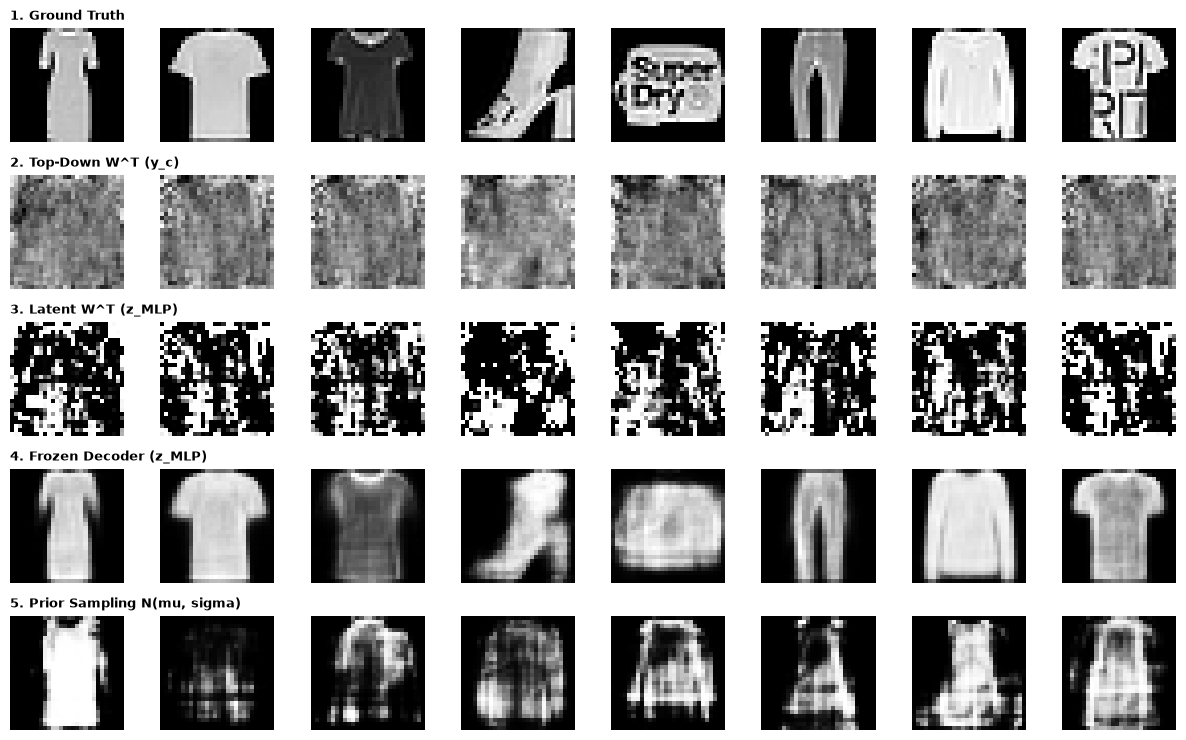

In [19]:
# Tahap 5: Sampling acak N(mu_z, diag(sigma_z^2))
mu_z = all_z_mlp.mean(dim=0, keepdim=True).to(device)
sigma_z = all_z_mlp.std(dim=0, keepdim=True).to(device)

set_seed(SEED)
with torch.no_grad():
    z_rand = mu_z + sigma_z * torch.randn(8, 64, device=device)
    x_rand_mlp = frozen_decoder(z_rand)
    x_recon_vis = frozen_decoder(z_mlp_vis)

# Preview cepat hasil Tahap 2-5 (nanti panel Vanilla AE akan digabung ke Figur 3)
fig, axes = plt.subplots(5, 8, figsize=(12, 7.5))
rows = [
    ("1. Ground Truth", x_test_vis.cpu()),
    ("2. Top-Down W^T (y_c)", x_hat_topdown.cpu()),
    ("3. Latent W^T (z_MLP)", x_hat_latent_T.cpu()),
    ("4. Frozen Decoder (z_MLP)", x_recon_vis.cpu()),
    ("5. Prior Sampling N(mu, sigma)", x_rand_mlp.cpu()),
]

for r, (title, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/figures/preview_mlp_limitations.png", dpi=200)
plt.show()

# **AutoEncoder**

In [20]:
import time

LATENT_DIM = 64

class VanillaAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class SparseAE(VanillaAE):
    """Struktur identik dengan Vanilla AE, dilatih dengan tambahan penalti L1 pada representasi laten."""
    pass


class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = F.relu(self.fc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [21]:
EPOCHS_AE = 25
L1_LAMBDA = 1e-4

loss_history = {}
train_time_per_epoch = {}

# 1. Train Vanilla AE
set_seed(SEED)
vanilla_ae = VanillaAE().to(device)
opt_vae_plain = torch.optim.Adam(vanilla_ae.parameters(), lr=1e-3)
loss_history["Vanilla AE"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_AE + 1), desc="Training Vanilla AE")
for epoch in pbar:
    vanilla_ae.train()
    epoch_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_vae_plain.zero_grad()
        x_hat, _ = vanilla_ae(x)
        loss = F.mse_loss(x_hat, x)
        loss.backward()
        opt_vae_plain.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader)
    loss_history["Vanilla AE"].append(avg_loss)
    pbar.set_postfix(loss=f"{avg_loss:.5f}")
train_time_per_epoch["Vanilla AE"] = (time.time() - t0) / EPOCHS_AE
torch.save(vanilla_ae.state_dict(), "outputs/checkpoints/vanilla_ae.pt")

# 2. Train Sparse AE
set_seed(SEED)
sparse_ae = SparseAE().to(device)
opt_sae = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
loss_history["Sparse AE"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_AE + 1), desc="Training Sparse AE ")
for epoch in pbar:
    sparse_ae.train()
    epoch_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_sae.zero_grad()
        x_hat, z = sparse_ae(x)
        loss = F.mse_loss(x_hat, x) + L1_LAMBDA * torch.mean(torch.abs(z))
        loss.backward()
        opt_sae.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader)
    loss_history["Sparse AE"].append(avg_loss)
    pbar.set_postfix(loss=f"{avg_loss:.5f}")
train_time_per_epoch["Sparse AE"] = (time.time() - t0) / EPOCHS_AE
torch.save(sparse_ae.state_dict(), "outputs/checkpoints/sparse_ae.pt")

# 3. Train VAE
set_seed(SEED)
vae = VAE().to(device)
opt_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)
loss_history["VAE"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_AE + 1), desc="Training VAE       ")
for epoch in pbar:
    vae.train()
    epoch_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_vae.zero_grad()
        x_hat, mu, logvar = vae(x)
        bce = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
        kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        loss = bce + kld
        loss.backward()
        opt_vae.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader)
    loss_history["VAE"].append(avg_loss)
    pbar.set_postfix(loss=f"{avg_loss:.2f}")
train_time_per_epoch["VAE"] = (time.time() - t0) / EPOCHS_AE
torch.save(vae.state_dict(), "outputs/checkpoints/vae.pt")

Training Vanilla AE:   0%|          | 0/25 [00:00<?, ?it/s]

Training Sparse AE :   0%|          | 0/25 [00:00<?, ?it/s]

Training VAE       :   0%|          | 0/25 [00:00<?, ?it/s]

In [22]:
def evaluate_ae_model(model, loader, is_vae=False):
    model.eval()
    all_true, all_recon = [], []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            if is_vae:
                x_hat, _, _ = model(x)
            else:
                x_hat, _ = model(x)
            all_true.append(x.cpu())
            all_recon.append(x_hat.cpu())
    return compute_recon_metrics(torch.cat(all_true), torch.cat(all_recon))

ae_metrics = {
    "Vanilla AE": evaluate_ae_model(vanilla_ae, test_loader, is_vae=False),
    "Sparse AE": evaluate_ae_model(sparse_ae, test_loader, is_vae=False),
    "VAE": evaluate_ae_model(vae, test_loader, is_vae=True),
}

for name, m in ae_metrics.items():
    print(f"{name:12s} | MSE: {m['MSE']:.5f} | PSNR: {m['PSNR']:.2f} dB | SSIM: {m['SSIM']:.4f}")

Vanilla AE   | MSE: 0.00838 | PSNR: 20.77 dB | SSIM: 0.7895
Sparse AE    | MSE: 0.00844 | PSNR: 20.74 dB | SSIM: 0.7875
VAE          | MSE: 0.01556 | PSNR: 18.08 dB | SSIM: 0.6801


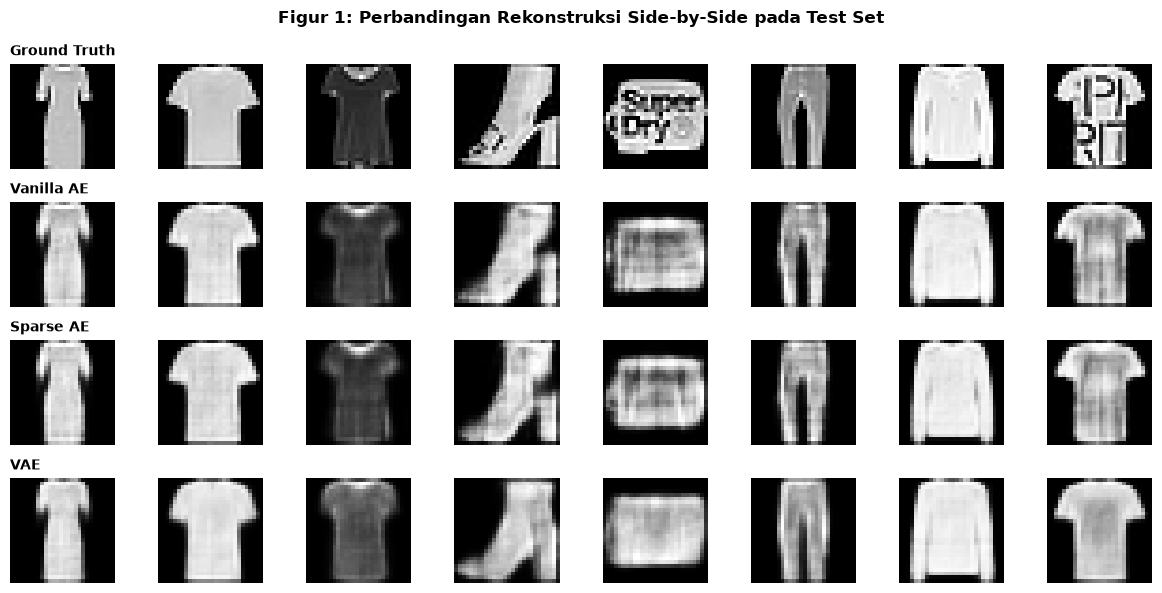

In [23]:
vanilla_ae.eval(); sparse_ae.eval(); vae.eval()
with torch.no_grad():
    rec_vanilla, _ = vanilla_ae(x_test_vis)
    rec_sparse, _ = sparse_ae(x_test_vis)
    rec_vae, _, _ = vae(x_test_vis)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
rows_fig1 = [
    ("Ground Truth", x_test_vis.cpu()),
    ("Vanilla AE", rec_vanilla.cpu()),
    ("Sparse AE", rec_sparse.cpu()),
    ("VAE", rec_vae.cpu()),
]

for r, (title, imgs) in enumerate(rows_fig1):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10, fontweight="bold")

plt.suptitle("Figur 1: Perbandingan Rekonstruksi Side-by-Side pada Test Set", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/figures/figur1_rekonstruksi.png", dpi=300, bbox_inches="tight")
plt.show()

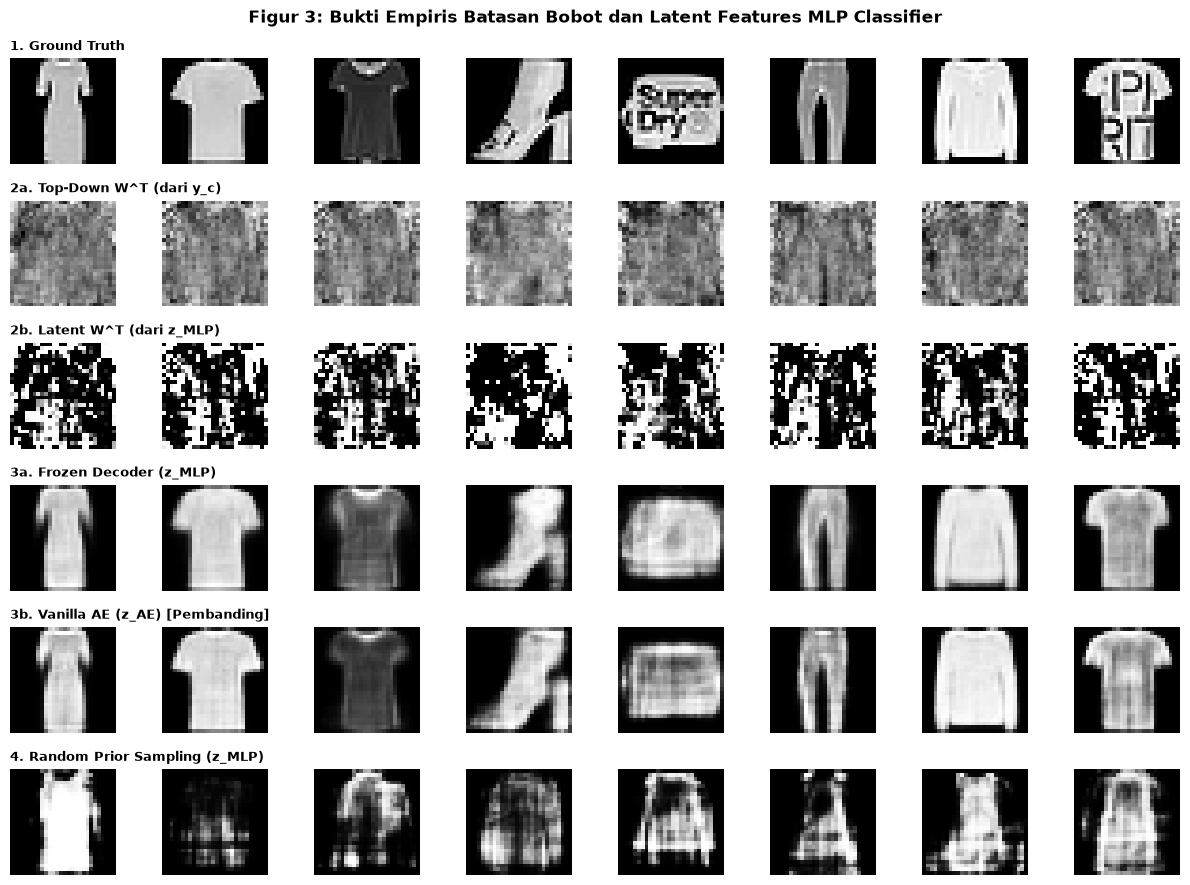

In [24]:
fig, axes = plt.subplots(6, 8, figsize=(12, 9))
rows_fig3 = [
    ("1. Ground Truth", x_test_vis.cpu()),
    ("2a. Top-Down W^T (dari y_c)", x_hat_topdown.cpu()),
    ("2b. Latent W^T (dari z_MLP)", x_hat_latent_T.cpu()),
    ("3a. Frozen Decoder (z_MLP)", x_recon_vis.cpu()),
    ("3b. Vanilla AE (z_AE) [Pembanding]", rec_vanilla.cpu()),
    ("4. Random Prior Sampling (z_MLP)", x_rand_mlp.cpu()),
]

for r, (title, imgs) in enumerate(rows_fig3):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=9, fontweight="bold")

plt.suptitle("Figur 3: Bukti Empiris Batasan Bobot dan Latent Features MLP Classifier", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/figures/figur3_mlp_limitations.png", dpi=300, bbox_inches="tight")
plt.show()

# **GAN**

In [25]:
train_loader_gan, val_loader_gan, test_loader_gan = get_fashion_mnist_loaders(
    normalize_to_neg_one=True
)
x_gan_sample, _ = next(iter(train_loader_gan))
print(f"GAN/DDPM Batch shape: {x_gan_sample.shape} | Range: [{x_gan_sample.min():.2f}, {x_gan_sample.max():.2f}]")

GAN/DDPM Batch shape: torch.Size([128, 1, 28, 28]) | Range: [-1.00, 1.00]


In [26]:
NOISE_DIM = 100
EPOCHS_GAN = 30

class VanillaGenerator(nn.Module):
    def __init__(self, noise_dim=NOISE_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 784),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1),  # Output logits (untuk BCEWithLogitsLoss)
        )

    def forward(self, x):
        return self.net(x.view(x.size(0), -1)).squeeze(1)


set_seed(SEED)
vgan_G = VanillaGenerator(NOISE_DIM).to(device)
vgan_D = VanillaDiscriminator().to(device)

opt_vG = torch.optim.Adam(vgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_vD = torch.optim.Adam(vgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce_logits = nn.BCEWithLogitsLoss()

loss_history["Vanilla GAN_G"] = []
loss_history["Vanilla GAN_D"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_GAN + 1), desc="Training Vanilla GAN")
for epoch in pbar:
    vgan_G.train(); vgan_D.train()
    g_loss_ep, d_loss_ep = 0.0, 0.0

    for x_real, _ in train_loader_gan:
        x_real = x_real.to(device)
        bs = x_real.size(0)
        real_lbl = torch.ones(bs, device=device)
        fake_lbl = torch.zeros(bs, device=device)

        # 1. Update Discriminator: max log(D(x)) + log(1 - D(G(z)))
        opt_vD.zero_grad()
        z = torch.randn(bs, NOISE_DIM, device=device)
        x_fake = vgan_G(z).detach()
        loss_d = bce_logits(vgan_D(x_real), real_lbl) + bce_logits(vgan_D(x_fake), fake_lbl)
        loss_d.backward()
        opt_vD.step()

        # 2. Update Generator: max log(D(G(z)))
        opt_vG.zero_grad()
        z = torch.randn(bs, NOISE_DIM, device=device)
        x_fake = vgan_G(z)
        loss_g = bce_logits(vgan_D(x_fake), real_lbl)
        loss_g.backward()
        opt_vG.step()

        d_loss_ep += loss_d.item()
        g_loss_ep += loss_g.item()

    avg_d = d_loss_ep / len(train_loader_gan)
    avg_g = g_loss_ep / len(train_loader_gan)
    loss_history["Vanilla GAN_D"].append(avg_d)
    loss_history["Vanilla GAN_G"].append(avg_g)
    pbar.set_postfix(D_loss=f"{avg_d:.4f}", G_loss=f"{avg_g:.4f}")

train_time_per_epoch["Vanilla GAN"] = (time.time() - t0) / EPOCHS_GAN
torch.save(vgan_G.state_dict(), "outputs/checkpoints/vanilla_gan_G.pt")
torch.save(vgan_D.state_dict(), "outputs/checkpoints/vanilla_gan_D.pt")
print(f"Vanilla GAN selesai | {train_time_per_epoch['Vanilla GAN']:.2f}s/epoch")

Training Vanilla GAN:   0%|          | 0/30 [00:00<?, ?it/s]

Vanilla GAN selesai | 9.14s/epoch


In [27]:
def weights_init_dcgan(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class DCGANGenerator(nn.Module):
    def __init__(self, noise_dim=NOISE_DIM):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (N, 100, 1, 1) -> (N, 256, 7, 7)
            nn.ConvTranspose2d(noise_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # (N, 256, 7, 7) -> (N, 128, 14, 14)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # (N, 128, 14, 14) -> (N, 1, 28, 28)
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), z.size(1), 1, 1))


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # (N, 1, 28, 28) -> (N, 64, 14, 14) (tanpa BatchNorm di layer pertama)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # (N, 64, 14, 14) -> (N, 128, 7, 7)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # (N, 128, 7, 7) -> (N, 1, 1, 1)
            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
        )

    def forward(self, x):
        return self.net(x).view(-1)


set_seed(SEED)
dcgan_G = DCGANGenerator(NOISE_DIM).to(device)
dcgan_D = DCGANDiscriminator().to(device)
dcgan_G.apply(weights_init_dcgan)
dcgan_D.apply(weights_init_dcgan)

opt_dcG = torch.optim.Adam(dcgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_dcD = torch.optim.Adam(dcgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

loss_history["DCGAN_G"] = []
loss_history["DCGAN_D"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_GAN + 1), desc="Training DCGAN      ")
for epoch in pbar:
    dcgan_G.train(); dcgan_D.train()
    g_loss_ep, d_loss_ep = 0.0, 0.0

    for x_real, _ in train_loader_gan:
        x_real = x_real.to(device)
        bs = x_real.size(0)
        real_lbl = torch.ones(bs, device=device)
        fake_lbl = torch.zeros(bs, device=device)

        # 1. Update Discriminator
        opt_dcD.zero_grad()
        z = torch.randn(bs, NOISE_DIM, device=device)
        x_fake = dcgan_G(z).detach()
        loss_d = bce_logits(dcgan_D(x_real), real_lbl) + bce_logits(dcgan_D(x_fake), fake_lbl)
        loss_d.backward()
        opt_dcD.step()

        # 2. Update Generator
        opt_dcG.zero_grad()
        z = torch.randn(bs, NOISE_DIM, device=device)
        x_fake = dcgan_G(z)
        loss_g = bce_logits(dcgan_D(x_fake), real_lbl)
        loss_g.backward()
        opt_dcG.step()

        d_loss_ep += loss_d.item()
        g_loss_ep += loss_g.item()

    avg_d = d_loss_ep / len(train_loader_gan)
    avg_g = g_loss_ep / len(train_loader_gan)
    loss_history["DCGAN_D"].append(avg_d)
    loss_history["DCGAN_G"].append(avg_g)
    pbar.set_postfix(D_loss=f"{avg_d:.4f}", G_loss=f"{avg_g:.4f}")

train_time_per_epoch["DCGAN"] = (time.time() - t0) / EPOCHS_GAN
torch.save(dcgan_G.state_dict(), "outputs/checkpoints/dcgan_G.pt")
torch.save(dcgan_D.state_dict(), "outputs/checkpoints/dcgan_D.pt")
print(f"DCGAN selesai | {train_time_per_epoch['DCGAN']:.2f}s/epoch")

Training DCGAN      :   0%|          | 0/30 [00:00<?, ?it/s]

DCGAN selesai | 9.21s/epoch


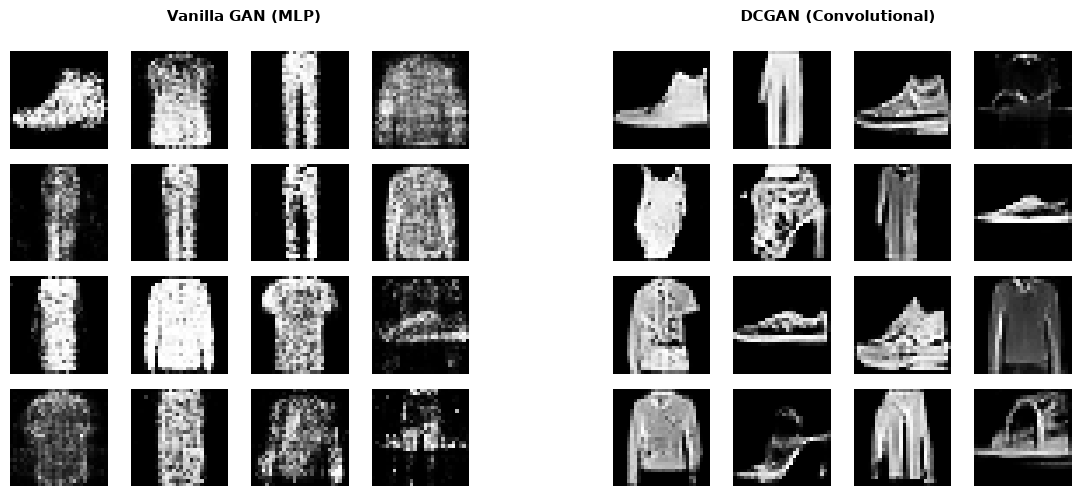

In [28]:
vgan_G.eval(); dcgan_G.eval()
set_seed(SEED)
with torch.no_grad():
    z_fixed = torch.randn(16, NOISE_DIM, device=device)
    # Konversi balik dari [-1, 1] ke [0, 1]
    samples_vgan = (vgan_G(z_fixed).cpu() + 1) / 2.0
    samples_dcgan = (dcgan_G(z_fixed).cpu() + 1) / 2.0

fig, axes = plt.subplots(4, 9, figsize=(11, 5))
for i in range(16):
    r, c = divmod(i, 4)
    axes[r, c].imshow(samples_vgan[i, 0], cmap="gray")
    axes[r, c].axis("off")
    axes[r, c + 5].imshow(samples_dcgan[i, 0], cmap="gray")
    axes[r, c + 5].axis("off")
for r in range(4):
    axes[r, 4].axis("off")  # Spacer tengah

fig.text(0.23, 0.96, "Vanilla GAN (MLP)", ha="center", fontsize=11, fontweight="bold")
fig.text(0.77, 0.96, "DCGAN (Convolutional)", ha="center", fontsize=11, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# **DDPM (Denoising Diffusion Probabilistic Models)**

In [29]:
import math

class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=-1)


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.time_mlp = nn.Linear(time_dim, out_ch)

    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time_mlp(F.silu(t_emb))[:, :, None, None]
        h = F.silu(self.norm2(self.conv2(h)))
        return h


class MiniUNet(nn.Module):
    def __init__(self, time_dim: int = 128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmb(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
        )
        # Encoder: 28x28 -> 14x14 -> 7x7
        self.down1 = ConvBlock(1, 64, time_dim)
        self.pool1 = nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1)
        self.down2 = ConvBlock(64, 128, time_dim)
        self.pool2 = nn.Conv2d(128, 128, kernel_size=4, stride=2, padding=1)

        # Bottleneck: 7x7
        self.bot = ConvBlock(128, 256, time_dim)

        # Decoder: 7x7 -> 14x14 -> 28x28
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1)
        self.dec2 = ConvBlock(256, 128, time_dim)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)
        self.dec1 = ConvBlock(128, 64, time_dim)

        self.out_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        d1 = self.down1(x, t_emb)                 # (N, 64, 28, 28)
        d2 = self.down2(self.pool1(d1), t_emb)    # (N, 128, 14, 14)
        b = self.bot(self.pool2(d2), t_emb)       # (N, 256, 7, 7)

        u2 = self.up2(b)                          # (N, 128, 14, 14)
        u2 = self.dec2(torch.cat([u2, d2], dim=1), t_emb)
        u1 = self.up1(u2)                         # (N, 64, 28, 28)
        u1 = self.dec1(torch.cat([u1, d1], dim=1), t_emb)
        return self.out_conv(u1)

In [30]:
T_STEPS = 200
EPOCHS_DDPM = 25

# Linear Beta Schedule
betas = torch.linspace(1e-4, 0.02, T_STEPS, device=device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

set_seed(SEED)
ddpm_model = MiniUNet(time_dim=128).to(device)
opt_ddpm = torch.optim.Adam(ddpm_model.parameters(), lr=2e-4)

loss_history["DDPM"] = []

t0 = time.time()
pbar = tqdm(range(1, EPOCHS_DDPM + 1), desc="Training DDPM       ")
for epoch in pbar:
    ddpm_model.train()
    epoch_loss = 0.0
    for x0, _ in train_loader_gan:  # Skala [-1, 1]
        x0 = x0.to(device)
        bs = x0.size(0)
        t = torch.randint(0, T_STEPS, (bs,), device=device).long()
        noise = torch.randn_like(x0)

        # Forward diffusion: x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * eps
        s_a = sqrt_alphas_cumprod[t][:, None, None, None]
        s_1ma = sqrt_one_minus_alphas_cumprod[t][:, None, None, None]
        xt = s_a * x0 + s_1ma * noise

        opt_ddpm.zero_grad()
        noise_pred = ddpm_model(xt, t)
        loss = F.mse_loss(noise_pred, noise)
        loss.backward()
        opt_ddpm.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader_gan)
    loss_history["DDPM"].append(avg_loss)
    pbar.set_postfix(mse_noise=f"{avg_loss:.5f}")

train_time_per_epoch["DDPM"] = (time.time() - t0) / EPOCHS_DDPM
torch.save(ddpm_model.state_dict(), "outputs/checkpoints/ddpm_unet.pt")
print(f"DDPM selesai | {train_time_per_epoch['DDPM']:.2f}s/epoch | Final Loss: {loss_history['DDPM'][-1]:.5f}")

Training DDPM       :   0%|          | 0/25 [00:00<?, ?it/s]

DDPM selesai | 15.17s/epoch | Final Loss: 0.07988


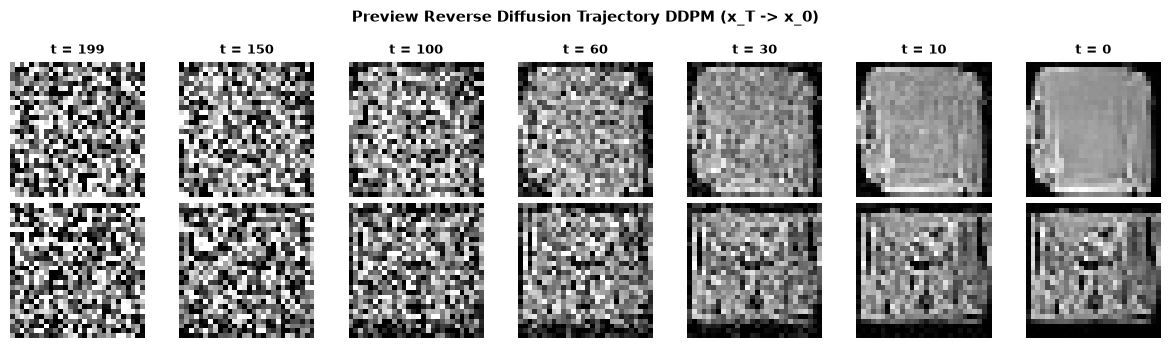

In [31]:
@torch.no_grad()
def sample_ddpm(model, n_samples=16, return_trajectory=False, save_steps=(199, 150, 100, 60, 30, 10, 0)):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    trajectory = {}

    for t_idx in reversed(range(T_STEPS)):
        t_batch = torch.full((n_samples,), t_idx, device=device, dtype=torch.long)
        eps_theta = model(x, t_batch)

        beta_t = betas[t_idx]
        alpha_t = alphas[t_idx]
        alpha_bar_t = alphas_cumprod[t_idx]

        # Rumus reverse step DDPM
        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * eps_theta
        )
        if t_idx > 0:
            x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
        else:
            x = mean

        if return_trajectory and t_idx in save_steps:
            trajectory[t_idx] = ((x.clamp(-1, 1).cpu() + 1) / 2.0)

    x_final = (x.clamp(-1, 1).cpu() + 1) / 2.0
    if return_trajectory:
        return x_final, trajectory
    return x_final

# Preview cepat proses denoising x_T -> x_0
set_seed(SEED)
ddpm_samples, ddpm_traj = sample_ddpm(ddpm_model, n_samples=16, return_trajectory=True)

steps_ordered = sorted(ddpm_traj.keys(), reverse=True)
fig, axes = plt.subplots(2, len(steps_ordered), figsize=(12, 3.5))
for col, step in enumerate(steps_ordered):
    for row in range(2):
        axes[row, col].imshow(ddpm_traj[step][row, 0], cmap="gray")
        axes[row, col].axis("off")
    axes[0, col].set_title(f"t = {step}", fontsize=9, fontweight="bold")

plt.suptitle("Preview Reverse Diffusion Trajectory DDPM (x_T -> x_0)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [32]:
def measure_latency_ms(fn, n_warmup=5, n_runs=30):
    """Mengukur rata-rata latensi inferensi dalam milidetik (ms) untuk 1 batch (64 sampel)."""
    with torch.no_grad():
        for _ in range(n_warmup):
            fn()
        if device.type == "cuda":
            torch.cuda.synchronize()

        t_start = time.perf_counter()
        for _ in range(n_runs):
            fn()
        if device.type == "cuda":
            torch.cuda.synchronize()
        t_end = time.perf_counter()

    return ((t_end - t_start) / n_runs) * 1000.0  # ms

vanilla_ae.eval(); sparse_ae.eval(); vae.eval()
vgan_G.eval(); dcgan_G.eval(); ddpm_model.eval()

# Siapkan dummy input ukuran batch 64
x_b64 = next(iter(test_loader))[0][:64].to(device)
z_ae_b64 = torch.randn(64, LATENT_DIM, device=device)
z_gan_b64 = torch.randn(64, NOISE_DIM, device=device)

inference_latency_ms = {
    "Vanilla AE": measure_latency_ms(lambda: vanilla_ae(x_b64)),
    "Sparse AE": measure_latency_ms(lambda: sparse_ae(x_b64)),
    "VAE": measure_latency_ms(lambda: vae.decode(z_ae_b64)),
    "Vanilla GAN": measure_latency_ms(lambda: vgan_G(z_gan_b64)),
    "DCGAN": measure_latency_ms(lambda: dcgan_G(z_gan_b64)),
    # DDPM butuh 200 langkah iteratif, cukup 1 warmup & 3 runs agar cepat
    "DDPM": measure_latency_ms(lambda: sample_ddpm(ddpm_model, n_samples=64), n_warmup=1, n_runs=3),
}

for name, lat in inference_latency_ms.items():
    print(f"{name:12s} | Inference Latency (batch 64): {lat:.2f} ms")

Vanilla AE   | Inference Latency (batch 64): 0.21 ms
Sparse AE    | Inference Latency (batch 64): 0.19 ms
VAE          | Inference Latency (batch 64): 0.10 ms
Vanilla GAN  | Inference Latency (batch 64): 0.13 ms
DCGAN        | Inference Latency (batch 64): 1.36 ms
DDPM         | Inference Latency (batch 64): 727.22 ms


In [33]:
import json
import pandas as pd
from torchmetrics.image.fid import FrechetInceptionDistance

def to_rgb_uint8(imgs_01: torch.Tensor) -> torch.Tensor:
    """Konversi tensor grayscale [0, 1] -> RGB uint8 [0, 255] untuk InceptionV3 FID."""
    imgs = (imgs_01.clamp(0, 1) * 255).to(torch.uint8)
    return imgs.repeat(1, 3, 1, 1)

def compute_fid_score(real_imgs_01: torch.Tensor, fake_imgs_01: torch.Tensor, batch_size=128) -> float:
    fid = FrechetInceptionDistance(feature=2048).to(device)
    for i in range(0, len(real_imgs_01), batch_size):
        fid.update(to_rgb_uint8(real_imgs_01[i:i+batch_size]).to(device), real=True)
    for i in range(0, len(fake_imgs_01), batch_size):
        fid.update(to_rgb_uint8(fake_imgs_01[i:i+batch_size]).to(device), real=False)
    return float(fid.compute().item())

N_FID = 2000  # 2000 sampel sintetis vs 2000 sampel asli Test Set
set_seed(SEED)

# 1. Kumpulkan 2000 citra asli dari Test Set
real_list = []
for x, _ in test_loader:
    real_list.append(x)
    if sum(len(t) for t in real_list) >= N_FID:
        break
real_fid = torch.cat(real_list, dim=0)[:N_FID]

# 2. Generate 2000 sampel dari tiap model generatif
@torch.no_grad()
def generate_samples_batched(gen_fn, total=N_FID, bs=256):
    out = []
    for i in range(0, total, bs):
        cur_bs = min(bs, total - i)
        out.append(gen_fn(cur_bs).cpu())
    return torch.cat(out, dim=0)

print("Menghasilkan sampel sintetis untuk evaluasi FID...")
fake_vae = generate_samples_batched(lambda n: vae.decode(torch.randn(n, LATENT_DIM, device=device)))
fake_vgan = generate_samples_batched(lambda n: (vgan_G(torch.randn(n, NOISE_DIM, device=device)) + 1) / 2.0)
fake_dcgan = generate_samples_batched(lambda n: (dcgan_G(torch.randn(n, NOISE_DIM, device=device)) + 1) / 2.0)
fake_ddpm = generate_samples_batched(lambda n: sample_ddpm(ddpm_model, n_samples=n), bs=256)

fid_scores = {
    "VAE": compute_fid_score(real_fid, fake_vae),
    "Vanilla GAN": compute_fid_score(real_fid, fake_vgan),
    "DCGAN": compute_fid_score(real_fid, fake_dcgan),
    "DDPM": compute_fid_score(real_fid, fake_ddpm),
}

# 3. Susun Tabel Komparasi Metrik Numerik (Bagian IV)
summary_rows = [
    {
        "Arsitektur Model": "Vanilla Autoencoder",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(train_time_per_epoch["Vanilla AE"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["Vanilla AE"], 2),
        "Test MSE": round(ae_metrics["Vanilla AE"]["MSE"], 5),
        "Test PSNR (dB)": round(ae_metrics["Vanilla AE"]["PSNR"], 2),
        "Test SSIM": round(ae_metrics["Vanilla AE"]["SSIM"], 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Sparse Autoencoder",
        "Dim Laten": "64 (Sparse L1)",
        "Training Time / Epoch (s)": round(train_time_per_epoch["Sparse AE"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["Sparse AE"], 2),
        "Test MSE": round(ae_metrics["Sparse AE"]["MSE"], 5),
        "Test PSNR (dB)": round(ae_metrics["Sparse AE"]["PSNR"], 2),
        "Test SSIM": round(ae_metrics["Sparse AE"]["SSIM"], 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Variational Autoencoder (VAE)",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(train_time_per_epoch["VAE"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["VAE"], 2),
        "Test MSE": round(ae_metrics["VAE"]["MSE"], 5),
        "Test PSNR (dB)": round(ae_metrics["VAE"]["PSNR"], 2),
        "Test SSIM": round(ae_metrics["VAE"]["SSIM"], 4),
        "FID Score": round(fid_scores["VAE"], 2),
        "Kestabilan Training": "Stabil / Konvergen",
    },
    {
        "Arsitektur Model": "Vanilla GAN (MLP)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(train_time_per_epoch["Vanilla GAN"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["Vanilla GAN"], 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(fid_scores["Vanilla GAN"], 2),
        "Kestabilan Training": "Rentan Osilasi / Mode Collapse",
    },
    {
        "Arsitektur Model": "DCGAN",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(train_time_per_epoch["DCGAN"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["DCGAN"], 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(fid_scores["DCGAN"], 2),
        "Kestabilan Training": "Cukup Stabil (Sensitif Arsitektur)",
    },
    {
        "Arsitektur Model": "DDPM",
        "Dim Laten": "28x28 (Dimensi Citra)",
        "Training Time / Epoch (s)": round(train_time_per_epoch["DDPM"], 2),
        "Latency (ms / batch 64)": round(inference_latency_ms["DDPM"], 2),
        "Test MSE": "N/A (Denoising Model)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(fid_scores["DDPM"], 2),
        "Kestabilan Training": "Sangat Stabil",
    },
]

df_metrics = pd.DataFrame(summary_rows)
df_metrics.to_csv("outputs/logs/tabel_metrik_komparatif.csv", index=False)
with open("outputs/logs/loss_history.json", "w") as f:
    json.dump(loss_history, f, indent=2)

display(df_metrics)

Menghasilkan sampel sintetis untuk evaluasi FID...


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\THOMPC/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:17<00:00, 5.31MB/s]


,Arsitektur Model,Dim Laten,Training Time / Epoch (s),Latency (ms / batch 64),Test MSE,Test PSNR (dB),Test SSIM,FID Score,Kestabilan Training
0,Vanilla Autoencoder,64,6.71,0.21,0.00838,20.77,0.7895,N/A (Latent Voids),Stabil / Konvergen
1,Sparse Autoencoder,64 (Sparse L1),6.86,0.19,0.00844,20.74,0.7875,N/A (Latent Voids),Stabil / Konvergen
2,Variational Autoencoder (VAE),64,7.59,0.10,0.01556,18.08,0.6801,94.12,Stabil / Konvergen
3,Vanilla GAN (MLP),100 (Prior Noise),9.14,0.13,N/A (Tanpa Encoder),N/A,N/A,147.31,Rentan Osilasi / Mode Collapse
4,DCGAN,100 (Prior Noise),9.21,1.36,N/A (Tanpa Encoder),N/A,N/A,29.1,Cukup Stabil (Sensitif Arsitektur)
5,DDPM,28x28 (Dimensi Citra),15.17,727.22,N/A (Denoising Model),N/A,N/A,91.54,Sangat Stabil


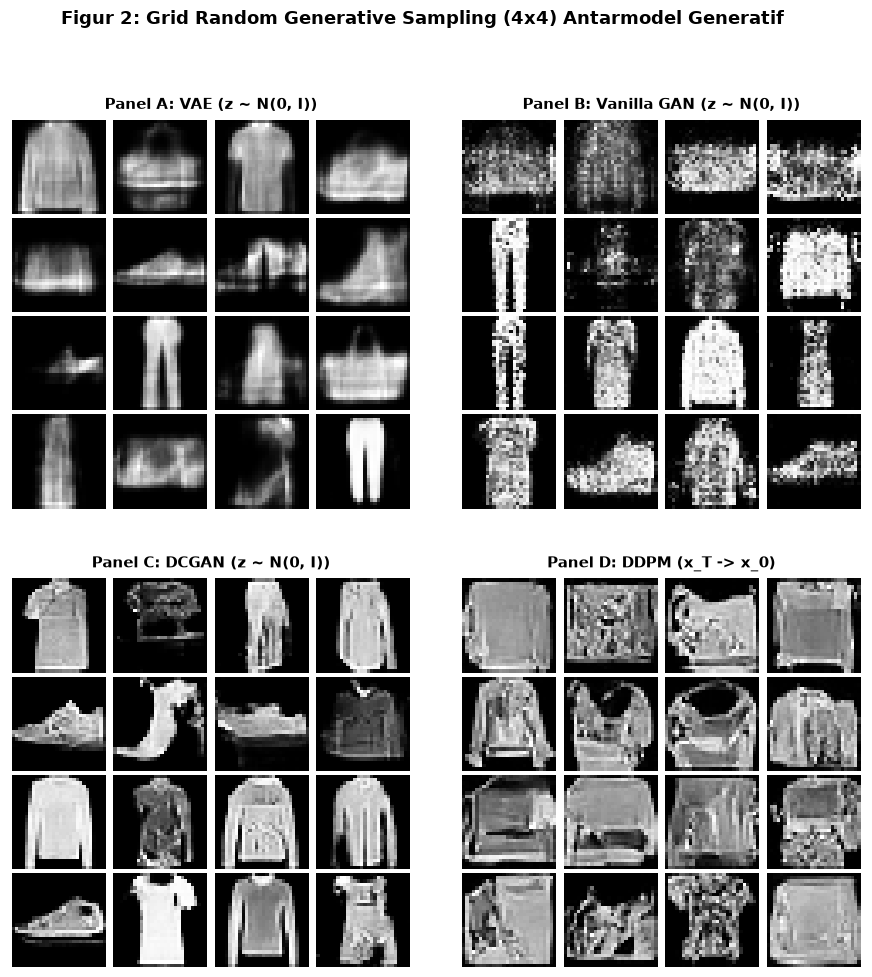

In [34]:
set_seed(SEED)
with torch.no_grad():
    grid_vae = vae.decode(torch.randn(16, LATENT_DIM, device=device)).cpu()
    grid_vgan = (vgan_G(torch.randn(16, NOISE_DIM, device=device)).cpu() + 1) / 2.0
    grid_dcgan = (dcgan_G(torch.randn(16, NOISE_DIM, device=device)).cpu() + 1) / 2.0
    grid_ddpm = ddpm_samples[:16]  # Sudah di-generate di Cell 20

panels = [
    ("Panel A: VAE (z ~ N(0, I))", grid_vae),
    ("Panel B: Vanilla GAN (z ~ N(0, I))", grid_vgan),
    ("Panel C: DCGAN (z ~ N(0, I))", grid_dcgan),
    ("Panel D: DDPM (x_T -> x_0)", grid_ddpm),
]

fig = plt.figure(figsize=(11, 11))
outer = fig.add_gridspec(2, 2, wspace=0.12, hspace=0.18)

for idx, (title, imgs) in enumerate(panels):
    inner = outer[idx].subgridspec(4, 4, wspace=0.04, hspace=0.04)
    ax_title = fig.add_subplot(outer[idx])
    ax_title.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax_title.axis("off")

    for j in range(16):
        ax = fig.add_subplot(inner[j])
        ax.imshow(imgs[j, 0], cmap="gray")
        ax.axis("off")

fig.suptitle("Figur 2: Grid Random Generative Sampling (4x4) Antarmodel Generatif", fontsize=13, fontweight="bold", y=0.98)
plt.savefig("outputs/figures/figur2_random_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

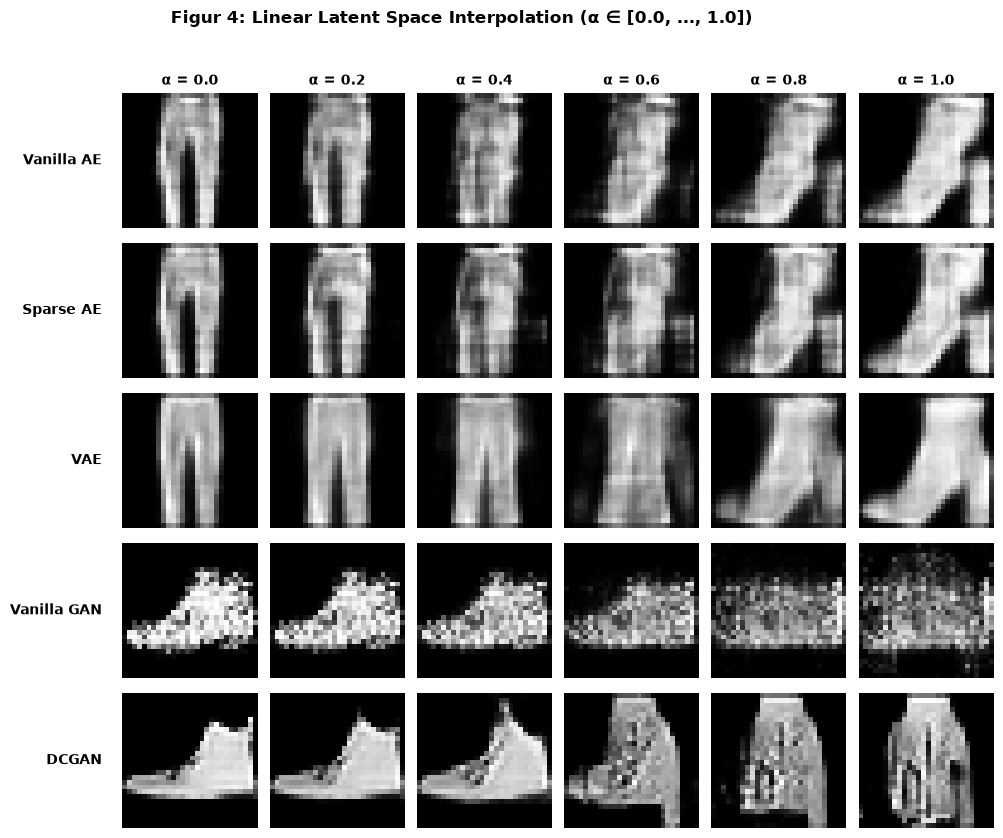

In [35]:
alphas_interp = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Cari 2 citra kontras dari Test Set: Kelas 1 (Trouser) dan Kelas 9 (Ankle boot)
x_A, x_B = None, None
for x_b, y_b in test_loader:
    for i in range(len(y_b)):
        if y_b[i].item() == 1 and x_A is None:
            x_A = x_b[i:i+1].to(device)
        elif y_b[i].item() == 9 and x_B is None:
            x_B = x_b[i:i+1].to(device)
    if x_A is not None and x_B is not None:
        break

def interpolate_latents(zA, zB, decode_fn):
    imgs = []
    for a in alphas_interp:
        z_a = (1.0 - a) * zA + a * zB
        imgs.append(decode_fn(z_a).cpu()[0, 0])
    return imgs

set_seed(SEED)
with torch.no_grad():
    # AE, Sparse AE, VAE: encode citra kontras x_A & x_B
    row_vanilla = interpolate_latents(vanilla_ae.encode(x_A), vanilla_ae.encode(x_B), vanilla_ae.decode)
    row_sparse = interpolate_latents(sparse_ae.encode(x_A), sparse_ae.encode(x_B), sparse_ae.decode)
    mu_A, _ = vae.encode(x_A)
    mu_B, _ = vae.encode(x_B)
    row_vae = interpolate_latents(mu_A, mu_B, vae.decode)

    # Vanilla GAN & DCGAN: interpolasi antara 2 titik prior noise acak z_A & z_B
    z_gan_A = torch.randn(1, NOISE_DIM, device=device)
    z_gan_B = torch.randn(1, NOISE_DIM, device=device)
    row_vgan = interpolate_latents(z_gan_A, z_gan_B, lambda z: (vgan_G(z) + 1) / 2.0)
    row_dcgan = interpolate_latents(z_gan_A, z_gan_B, lambda z: (dcgan_G(z) + 1) / 2.0)

interp_rows = [
    ("Vanilla AE", row_vanilla),
    ("Sparse AE", row_sparse),
    ("VAE", row_vae),
    ("Vanilla GAN", row_vgan),
    ("DCGAN", row_dcgan),
]

fig, axes = plt.subplots(5, len(alphas_interp), figsize=(11, 8.5))
for r, (name, imgs) in enumerate(interp_rows):
    for c, a in enumerate(alphas_interp):
        axes[r, c].imshow(imgs[c], cmap="gray")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"α = {a:.1f}", fontsize=10, fontweight="bold")
    axes[r, 0].text(-0.15, 0.5, name, va="center", ha="right", transform=axes[r, 0].transAxes, fontsize=10, fontweight="bold")

plt.suptitle("Figur 4: Linear Latent Space Interpolation (α ∈ [0.0, ..., 1.0])", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0.08, 0, 1, 0.96])
plt.savefig("outputs/figures/figur4_latent_interpolation.png", dpi=300, bbox_inches="tight")
plt.show()

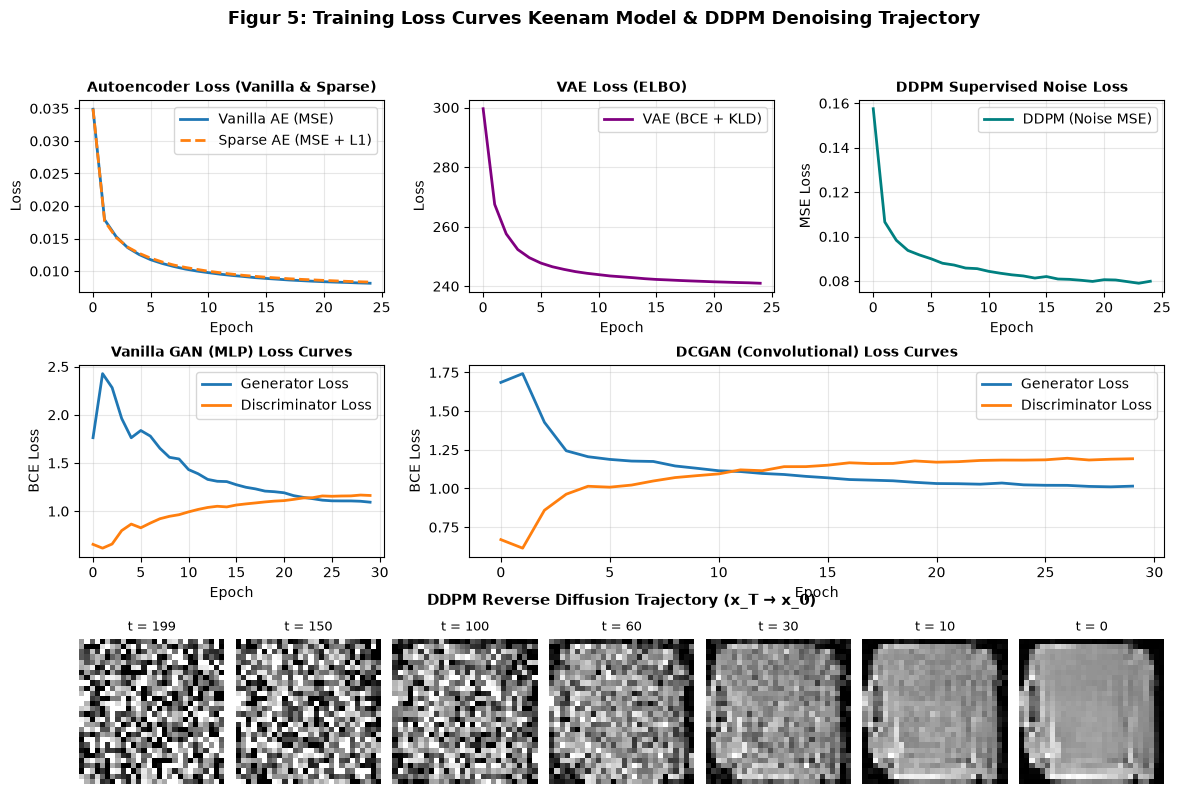

In [36]:
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.85], hspace=0.4, wspace=0.28)

# 1. Vanilla AE & Sparse AE
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(loss_history["Vanilla AE"], label="Vanilla AE (MSE)", linewidth=2)
ax1.plot(loss_history["Sparse AE"], label="Sparse AE (MSE + L1)", linewidth=2, linestyle="--")
ax1.set_title("Autoencoder Loss (Vanilla & Sparse)", fontweight="bold", fontsize=10)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.grid(alpha=0.3)

# 2. VAE
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(loss_history["VAE"], color="purple", label="VAE (BCE + KLD)", linewidth=2)
ax2.set_title("VAE Loss (ELBO)", fontweight="bold", fontsize=10)
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss"); ax2.legend(); ax2.grid(alpha=0.3)

# 3. DDPM Noise Prediction Loss
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(loss_history["DDPM"], color="teal", label="DDPM (Noise MSE)", linewidth=2)
ax3.set_title("DDPM Supervised Noise Loss", fontweight="bold", fontsize=10)
ax3.set_xlabel("Epoch"); ax3.set_ylabel("MSE Loss"); ax3.legend(); ax3.grid(alpha=0.3)

# 4. Vanilla GAN (G & D Loss)
ax4 = fig.add_subplot(gs[1, 0:1])
ax4.plot(loss_history["Vanilla GAN_G"], label="Generator Loss", linewidth=2)
ax4.plot(loss_history["Vanilla GAN_D"], label="Discriminator Loss", linewidth=2)
ax4.set_title("Vanilla GAN (MLP) Loss Curves", fontweight="bold", fontsize=10)
ax4.set_xlabel("Epoch"); ax4.set_ylabel("BCE Loss"); ax4.legend(); ax4.grid(alpha=0.3)

# 5. DCGAN (G & D Loss)
ax5 = fig.add_subplot(gs[1, 1:3])
ax5.plot(loss_history["DCGAN_G"], label="Generator Loss", linewidth=2)
ax5.plot(loss_history["DCGAN_D"], label="Discriminator Loss", linewidth=2)
ax5.set_title("DCGAN (Convolutional) Loss Curves", fontweight="bold", fontsize=10)
ax5.set_xlabel("Epoch"); ax5.set_ylabel("BCE Loss"); ax5.legend(); ax5.grid(alpha=0.3)

# 6. Panel Bawah: DDPM Reverse Diffusion Trajectory (x_T -> x_0)
steps_ordered = sorted(ddpm_traj.keys(), reverse=True)
gs_traj = gs[2, :].subgridspec(1, len(steps_ordered), wspace=0.08)
ax_traj_title = fig.add_subplot(gs[2, :])
ax_traj_title.set_title("DDPM Reverse Diffusion Trajectory (x_T → x_0)", fontweight="bold", fontsize=11, pad=18)
ax_traj_title.axis("off")

for idx, step in enumerate(steps_ordered):
    ax_t = fig.add_subplot(gs_traj[0, idx])
    ax_t.imshow(ddpm_traj[step][0, 0], cmap="gray")
    ax_t.set_title(f"t = {step}", fontsize=9)
    ax_t.axis("off")

fig.suptitle("Figur 5: Training Loss Curves Keenam Model & DDPM Denoising Trajectory", fontsize=13, fontweight="bold", y=0.98)
plt.savefig("outputs/figures/figur5_loss_and_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()